# A simple xroms plotting recipe for the EAC ROMS model

This notebook opens only the history files needed for a short date range and demonstrates three common plots:

1. a surface field,
2. a field interpolated to a fixed depth, and
3. a vertical section.

The helper functions work with variables on the ROMS rho, u, v, or psi grids, provided xroms can identify their coordinates. Keep the requested date range and spatial extent small: ROMS output is large, even when xarray opens it lazily.

## 1. Environment and imports

On NCI, start Jupyter from a Python environment containing xroms 0.6.x, xarray, Dask, netCDF4, Cartopy, Matplotlib, NumPy, pandas, and cmocean. For example, use the same processing environment used by the EAC analysis scripts.

In [1]:
from pathlib import Path
import re

import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import xarray as xr
import xroms

## 2. Configuration

Edit this cell first. `MAX_DAYS` is a deliberate safety guard against accidentally opening years of model output. Depths supplied to the plotting functions are positive metres below sea level.

In [7]:
DATA_DIR = Path(
    "/g/data/yj27/users/cgk561/30yr_run_1993_2023_CK/"
    "output"
)
DATE_START = np.datetime64("1994-01-01T12:00")
DATE_END = np.datetime64("1994-01-03T12:00")
PLOT_TIME = np.datetime64("1994-01-02T12:00")
EXTENT = [148.0, 153.0, -38.0, -34.0]  # lon_min, lon_max, lat_min, lat_max
MAX_DAYS = 31

## 3. Select and load only the required files

The EAC history files are named `roms_his_<model-day>.nc`. `files_in_date_range` uses those model-day numbers and the decoded time in the first file to determine which files overlap the request. The selected files are then opened lazily with one model time per Dask chunk.

In [3]:
_HISTORY_FILE_RE = re.compile(r"roms_his_(\d+)\.nc$")


def _as_datetime64(value):
    """Return a nanosecond datetime64 with a clear error for invalid input."""
    try:
        return np.datetime64(pd.Timestamp(value), "ns")
    except (TypeError, ValueError) as exc:
        raise ValueError(f"Could not interpret {value!r} as a date/time") from exc


def files_in_date_range(files, date_start, date_end, time_var="ocean_time"):
    """Return sorted EAC ROMS history files that overlap a date range.

    This assumes filenames of the form ``roms_his_<model-day>.nc`` and
    regularly spaced model-day numbers, as used by this EAC simulation.
    Only the first file is opened, and only to decode its first time value.
    """
    date_start = _as_datetime64(date_start)
    date_end = _as_datetime64(date_end)
    if date_start > date_end:
        raise ValueError("date_start must be earlier than or equal to date_end")

    parsed = []
    for file in map(Path, files):
        match = _HISTORY_FILE_RE.search(file.name)
        if match is None:
            raise ValueError(
                f"Unexpected history filename {file.name!r}; expected "
                "roms_his_<model-day>.nc"
            )
        parsed.append((int(match.group(1)), file))

    if not parsed:
        raise FileNotFoundError("No ROMS history files were supplied")

    parsed.sort(key=lambda item: item[0])
    model_days = np.asarray([item[0] for item in parsed], dtype=int)
    sorted_files = [item[1] for item in parsed]
    if model_days.size < 2:
        raise ValueError(
            "At least two history filenames are needed to infer days per file"
        )

    day_steps = np.diff(model_days)
    if np.any(day_steps <= 0):
        raise ValueError("History-file model days must be unique and increasing")
    days_per_file = int(np.median(day_steps))
    if not np.all(day_steps == days_per_file):
        raise ValueError("History filenames are not regularly spaced in model days")

    with xr.open_dataset(sorted_files[0], decode_times=True, cache=False) as first_ds:
        if time_var not in first_ds:
            raise KeyError(
                f"Time variable {time_var!r} is absent from {sorted_files[0]}"
            )
        if first_ds[time_var].size == 0:
            raise ValueError(f"Time variable {time_var!r} is empty")
        first_time = _as_datetime64(first_ds[time_var].values[0])

    base_day = model_days[0]
    selected = []
    for model_day, file in zip(model_days, sorted_files):
        file_start = first_time + np.timedelta64(int(model_day - base_day), "D")
        file_stop = file_start + np.timedelta64(days_per_file, "D")
        # Files cover half-open intervals [file_start, file_stop).
        if file_start <= date_end and file_stop > date_start:
            selected.append(file)

    if not selected:
        raise FileNotFoundError(
            f"No ROMS history files overlap {date_start} to {date_end}"
        )
    return selected


def _spatial_indexers(ds, extent):
    """Build ROMS staggered-grid indexers for a lon/lat bounding box."""
    if extent is None:
        return {}
    if len(extent) != 4:
        raise ValueError("extent must be [lon_min, lon_max, lat_min, lat_max]")

    lon_min, lon_max, lat_min, lat_max = map(float, extent)
    if lon_min >= lon_max or lat_min >= lat_max:
        raise ValueError("extent minimums must be smaller than maximums")
    if "lon_rho" not in ds or "lat_rho" not in ds:
        raise KeyError("Dataset must contain lon_rho and lat_rho")

    lon = np.asarray(ds["lon_rho"].values)
    lat = np.asarray(ds["lat_rho"].values)
    inside = (
        np.isfinite(lon)
        & np.isfinite(lat)
        & (lon >= lon_min)
        & (lon <= lon_max)
        & (lat >= lat_min)
        & (lat <= lat_max)
    )
    if not inside.any():
        raise ValueError(f"extent {extent} does not overlap the ROMS rho grid")

    jj, ii = np.where(inside)
    # One rho-cell of padding keeps the requested boundary visible.
    j0 = max(int(jj.min()) - 1, 0)
    j1 = min(int(jj.max()) + 2, ds.sizes["eta_rho"])
    i0 = max(int(ii.min()) - 1, 0)
    i1 = min(int(ii.max()) + 2, ds.sizes["xi_rho"])
    if j1 - j0 < 2 or i1 - i0 < 2:
        raise ValueError("extent must include at least two rho cells per direction")

    requested = {
        "eta_rho": slice(j0, j1),
        "eta_u": slice(j0, j1),
        "eta_v": slice(j0, j1 - 1),
        "eta_psi": slice(j0, j1 - 1),
        "xi_rho": slice(i0, i1),
        "xi_v": slice(i0, i1),
        "xi_u": slice(i0, i1 - 1),
        "xi_psi": slice(i0, i1 - 1),
    }
    return {dim: indexer for dim, indexer in requested.items() if dim in ds.dims}


def load_roms_dataset(
    data_dir,
    date_start,
    date_end,
    extent=None,
    max_days=31,
):
    """Open a short EAC ROMS subset lazily and attach the xroms grid."""
    data_dir = Path(data_dir).expanduser()
    date_start = _as_datetime64(date_start)
    date_end = _as_datetime64(date_end)
    if date_start > date_end:
        raise ValueError("date_start must be earlier than or equal to date_end")
    if max_days <= 0:
        raise ValueError("max_days must be positive")
    requested_days = (date_end - date_start) / np.timedelta64(1, "D")
    if requested_days > max_days:
        raise ValueError(
            f"Requested range is {requested_days:.1f} days; "
            f"the safety limit is {max_days} days. Change MAX_DAYS deliberately "
            "if a longer request is necessary."
        )
    if not data_dir.is_dir():
        raise FileNotFoundError(f"ROMS directory does not exist: {data_dir}")

    all_files = sorted(data_dir.glob("roms_his_*.nc"))
    selected_files = files_in_date_range(all_files, date_start, date_end)
    print(f"Opening {len(selected_files)} of {len(all_files)} history files:")
    for file in selected_files:
        print(f"  {file.name}")

    chunks = {"ocean_time": 1}
    if len(selected_files) == 1:
        ds = xr.open_dataset(selected_files[0], chunks=chunks)
    else:
        ds = xr.open_mfdataset(
            selected_files,
            combine="by_coords",
            compat="override",
            data_vars="minimal",
            coords="minimal",
            chunks=chunks,
            parallel=False,
        )

    ds = ds.sel(ocean_time=slice(date_start, date_end))
    if ds.sizes.get("ocean_time", 0) == 0:
        ds.close()
        raise ValueError("Selected files contain no model times in the requested range")
    ds = ds.isel(_spatial_indexers(ds, extent))
    ds, xgrid = xroms.roms_dataset(
        ds, include_Z0=True, include_cell_volume=False
    )
    ds.xroms.set_grid(xgrid)
    print(
        f"Loaded {ds.sizes['ocean_time']} times from "
        f"{pd.Timestamp(ds.ocean_time.values[0])} to "
        f"{pd.Timestamp(ds.ocean_time.values[-1])}"
    )
    return ds, xgrid

In [8]:
ds, xgrid = load_roms_dataset(
    DATA_DIR,
    DATE_START,
    DATE_END,
    extent=EXTENT,
    max_days=MAX_DAYS,
)
ds

Opening 1 of 365 history files:
  roms_his_01461.nc
Loaded 17 times from 1994-01-01 12:00:00 to 1994-01-03 12:00:00


<xarray.Dataset> Size: 2GB
Dimensions:        (tracer: 2, boundary: 4, s_rho: 30, s_w: 31, Nuser: 2,
                    eta_rho: 117, xi_rho: 171, xi_u: 170, eta_v: 116,
                    ocean_time: 17)
Coordinates: (12/31)
  * s_rho          (s_rho) float64 240B -0.9715 -0.9156 ... -0.0156 -0.004799
  * s_w            (s_w) float64 248B -1.0 -0.9433 -0.8883 ... -0.01 0.0
  * eta_rho        (eta_rho) int64 936B 0 1 2 3 4 5 ... 111 112 113 114 115 116
  * xi_rho         (xi_rho) int64 1kB 0 1 2 3 4 5 6 ... 165 166 167 168 169 170
  * xi_u           (xi_u) int64 1kB 0 1 2 3 4 5 6 ... 164 165 166 167 168 169
  * eta_v          (eta_v) int64 928B 0 1 2 3 4 5 6 ... 110 111 112 113 114 115
    ...             ...
    z_rho_v0       (s_rho, eta_v, xi_rho) float64 5MB dask.array<chunksize=(30, 116, 171), meta=np.ndarray>
    z_rho_psi0     (s_rho, eta_v, xi_u) float64 5MB dask.array<chunksize=(30, 116, 170), meta=np.ndarray>
    z_w0           (s_w, eta_rho, xi_rho) float64 5MB dask.array<chunksize=(31, 117, 171), meta=np.ndarray>
    z_w_u0         (s_w, eta_rho, xi_u) float64 5MB dask.array<chunksize=(31, 117, 170), meta=np.ndarray>
    z_w_v0         (s_w, eta_v, xi_rho) float64 5MB dask.array<chunksize=(31, 116, 171), meta=np.ndarray>
    z_w_psi0       (s_w, eta_v, xi_u) float64 5MB dask.array<chunksize=(31, 116, 170), meta=np.ndarray>
Dimensions without coordinates: tracer, boundary, Nuser
Data variables: (12/126)
    ntimes         int32 4B ...
    ndtfast        int32 4B ...
    dt             float64 8B ...
    dtfast         float64 8B ...
    dstart         datetime64[ns] 8B ...
    nHIS           int32 4B ...
    ...             ...
    dz_w_u0        (s_w, eta_rho, xi_u) float64 5MB dask.array<chunksize=(31, 117, 170), meta=np.ndarray>
    dz_v0          (s_rho, eta_v, xi_rho) float64 5MB dask.array<chunksize=(30, 116, 171), meta=np.ndarray>
    dz_w_v0        (s_w, eta_v, xi_rho) float64 5MB dask.array<chunksize=(31, 116, 171), meta=np.ndarray>
    dz_psi0        (s_rho, eta_v, xi_u) float64 5MB dask.array<chunksize=(30, 116, 170), meta=np.ndarray>
    dz_w_psi0      (s_w, eta_v, xi_u) float64 5MB dask.array<chunksize=(31, 116, 170), meta=np.ndarray>
    dA             (eta_rho, xi_rho) float64 160kB dask.array<chunksize=(117, 171), meta=np.ndarray>
Attributes: (12/34)
    file:              eac_his.nc
    format:            netCDF-3 64bit offset file
    Conventions:       CF-1.4, SGRID-0.3
    type:              ROMS/TOMS history file
    title:             EAC
    var_info:          /scratch/fu5/cgk561/10year_run_insideEnKFreanalysis/fr...
    ...                ...
    compiler_command:  /apps/openmpi/4.1.4/bin/mpif90
    compiler_flags:    -fp-model precise -heap-arrays -ip -O3 -traceback -che...
    tiling:            006x008
    history:           ROMS/TOMS, Version 4.2, Wednesday - July 30, 2025 -  1...
    ana_file:          ROMS/Functionals/ana_btflux.h, ROMS/Functionals/ana_sp...
    CPP_options:       EAC, ANA_BSFLUX, ANA_BTFLUX, ANA_SPONGE, ASSUMED_SHAPE...

## 4. Reusable plotting functions

`set_map` deliberately contains only the map elements used by the recipe. The plotting functions return the extracted DataArray as well as the Matplotlib objects, so the result can be inspected or reused in later analysis.

In [16]:
def set_map(extent, figsize=(9, 7), fig=None, ax=None):
    """Create or decorate a simple Plate Carrée map."""
    projection = ccrs.PlateCarree()
    if fig is None or ax is None:
        fig, ax = plt.subplots(
            figsize=figsize, subplot_kw={"projection": projection}
        )
    ax.set_extent(extent, crs=projection)
    ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="0.9", zorder=2)
    ax.coastlines(resolution="50m", linewidth=0.8, zorder=3)
    gridlines = ax.gridlines(
        crs=projection,
        draw_labels=True,
        linewidth=0.5,
        color="0.4",
        alpha=0.5,
        linestyle="--",
    )
    gridlines.top_labels = False
    gridlines.right_labels = False
    gridlines.xformatter = LONGITUDE_FORMATTER
    gridlines.yformatter = LATITUDE_FORMATTER
    gridlines.xlocator = mticker.MaxNLocator(6)
    gridlines.ylocator = mticker.MaxNLocator(6)
    return fig, ax


def _get_variable(ds, variable):
    if variable not in ds:
        available = ", ".join(sorted(ds.data_vars))
        raise KeyError(f"Variable {variable!r} is not in the dataset. Available: {available}")
    return ds[variable]


def _select_plot_time(da, time):
    """Select the nearest time without silently leaving the loaded range."""
    if "ocean_time" not in da.dims:
        return da, None
    requested = _as_datetime64(time)
    first = _as_datetime64(da.ocean_time.values[0])
    last = _as_datetime64(da.ocean_time.values[-1])
    if requested < first or requested > last:
        raise ValueError(
            f"Requested plot time {requested} is outside the loaded range "
            f"{first} to {last}"
        )
    selected = da.sel(ocean_time=requested, method="nearest")
    actual = _as_datetime64(selected.ocean_time.values)
    print(f"Requested time: {requested}; plotting nearest model time: {actual}")
    return selected, actual


def _vertical_dim(da):
    return next((dim for dim in ("s_rho", "s_w") if dim in da.dims), None)


def _horizontal_coordinates(da):
    lon_names = [
        name
        for name in da.coords
        if name.startswith("lon_") and da.coords[name].ndim == 2
    ]
    lat_names = [
        name
        for name in da.coords
        if name.startswith("lat_") and da.coords[name].ndim == 2
    ]
    for lon_name in lon_names:
        suffix = lon_name.removeprefix("lon_")
        lat_name = f"lat_{suffix}"
        if lat_name in lat_names and da[lon_name].dims == da[lat_name].dims:
            y_dim, x_dim = da[lon_name].dims
            if y_dim in da.dims and x_dim in da.dims:
                return lon_name, lat_name, y_dim, x_dim, suffix
    raise ValueError(
        f"Could not identify 2-D ROMS longitude/latitude coordinates for {da.name!r}"
    )


def _physical_depth_coordinate(da, vertical_dim):
    candidates = [
        name
        for name in da.coords
        if name.startswith("z_")
        and not name.endswith("0")
        and vertical_dim in da.coords[name].dims
    ]
    if not candidates:
        raise ValueError(
            f"No physical xroms depth coordinate is attached to {da.name!r}"
        )
    return candidates[0]


def _default_extent(lon, lat):
    return [
        float(lon.min()),
        float(lon.max()),
        float(lat.min()),
        float(lat.max()),
    ]


def _label(da):
    name = da.attrs.get("long_name", da.name or "variable")
    units = da.attrs.get("units")
    return f"{name} [{units}]" if units else name


def plot_horizontal_slice(
    ds,
    variable,
    time,
    depth_m=None,
    extent=None,
    cmap="viridis",
    vmin=None,
    vmax=None,
    figsize=(9, 7),
):
    """Plot a ROMS variable at the surface or at a fixed depth.

    ``depth_m`` is positive downward. If it is omitted for a 3-D variable,
    the top sigma layer is plotted. A 2-D variable must use depth_m=None.
    """
    da = _get_variable(ds, variable)
    da, actual_time = _select_plot_time(da, time)
    vertical_dim = _vertical_dim(da)

    if depth_m is None:
        field = da.isel({vertical_dim: -1}) if vertical_dim else da
        level_text = "surface layer" if vertical_dim else "2-D field"
    else:
        if vertical_dim is None:
            raise ValueError(
                f"{variable!r} is 2-D; use depth_m=None for this variable"
            )
        depth_m = float(depth_m)
        if not np.isfinite(depth_m) or depth_m <= 0:
            raise ValueError("depth_m must be a positive number")
        z_name = _physical_depth_coordinate(da, vertical_dim)
        deepest = float((-da[z_name].min(skipna=True)).compute())
        if depth_m > deepest:
            raise ValueError(
                f"Requested depth {depth_m:g} m exceeds the deepest available "
                f"model level in this subset ({deepest:.1f} m)"
            )
        field = xroms.isoslice(
            da.chunk({vertical_dim: -1}),
            np.asarray([-depth_m]),
            ds.xroms.xgrid,
            axis="Z",
        ).squeeze(drop=True)
        level_text = f"{depth_m:g} m depth"

    lon_name, lat_name, _, _, _ = _horizontal_coordinates(field)
    map_extent = extent or _default_extent(field[lon_name], field[lat_name])
    fig, ax = set_map(map_extent, figsize=figsize)
    artist = field.plot.pcolormesh(
        ax=ax,
        x=lon_name,
        y=lat_name,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False,
        add_labels=False,
        shading="auto",
        zorder=1,
    )
    fig.colorbar(artist, ax=ax, pad=0.03, label=_label(field))
    time_text = f" at {pd.Timestamp(actual_time)}" if actual_time is not None else ""
    ax.set_title(f"{_label(field)} — {level_text}{time_text}")
    return fig, ax, field


def _cumulative_distance_km(lon, lat):
    """Cumulative great-circle distance along coordinate pairs."""
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    if lon.size != lat.size or lon.ndim != 1:
        raise ValueError("lon and lat must be equal-length one-dimensional arrays")
    if lon.size == 0:
        return np.asarray([], dtype=float)
    lon1, lon2 = np.deg2rad(lon[:-1]), np.deg2rad(lon[1:])
    lat1, lat2 = np.deg2rad(lat[:-1]), np.deg2rad(lat[1:])
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    segment = 2 * 6371.0088 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    return np.concatenate(([0.0], np.cumsum(segment)))


def _coast_normal_indices(ds, da, target_lat, offshore_km):
    lon_name, lat_name, y_dim, x_dim, grid_name = _horizontal_coordinates(da)
    lon = np.asarray(da[lon_name].values)
    lat = np.asarray(da[lat_name].values)
    mask_name = f"mask_{grid_name}"
    if mask_name in ds:
        mask = np.asarray(ds[mask_name].values, dtype=bool)
    else:
        surface = da.isel({_vertical_dim(da): -1}, drop=True)
        if "ocean_time" in surface.dims:
            surface = surface.isel(ocean_time=0, drop=True)
        mask = np.isfinite(np.asarray(surface.values))
    if mask.shape != lon.shape:
        raise ValueError(f"{mask_name!r} does not match the variable's native grid")

    land_west = np.count_nonzero(~mask[:, 0])
    land_east = np.count_nonzero(~mask[:, -1])
    coast_side = "west" if land_west >= land_east else "east"
    valid_rows, coast_indices = [], []
    for j, row in enumerate(mask):
        wet = np.flatnonzero(row)
        if wet.size:
            valid_rows.append(j)
            coast_indices.append(int(wet[0] if coast_side == "west" else wet[-1]))
    if not valid_rows:
        raise ValueError("No wet model cells were found for this variable")

    valid_rows = np.asarray(valid_rows, dtype=int)
    coast_indices = np.asarray(coast_indices, dtype=int)
    coast_lats = lat[valid_rows, coast_indices]
    position = int(np.nanargmin(np.abs(coast_lats - float(target_lat))))
    j = int(valid_rows[position])
    coast_i = int(coast_indices[position])
    if coast_side == "west":
        candidate_i = np.arange(coast_i, lon.shape[1])
    else:
        candidate_i = np.arange(coast_i, -1, -1)
    candidate_i = candidate_i[mask[j, candidate_i]]
    distance = _cumulative_distance_km(lon[j, candidate_i], lat[j, candidate_i])
    offshore_km = float(offshore_km)
    if not np.isfinite(offshore_km) or offshore_km <= 0:
        raise ValueError("offshore_km must be a positive number")
    if distance[-1] < offshore_km:
        raise ValueError(
            f"Only {distance[-1]:.1f} km of wet grid is available from this coast; "
            f"requested {offshore_km:g} km"
        )
    stop = int(np.argmin(np.abs(distance - offshore_km))) + 1
    i_indices = candidate_i[:stop]
    j_indices = np.full(i_indices.size, j, dtype=int)
    return j_indices, i_indices, y_dim, x_dim


def _endpoint_indices(da, start, end):
    if start is None or end is None or len(start) != 2 or len(end) != 2:
        raise ValueError("start and end must each be (longitude, latitude) pairs")
    lon_name, lat_name, y_dim, x_dim, _ = _horizontal_coordinates(da)
    lon = np.asarray(da[lon_name].values)
    lat = np.asarray(da[lat_name].values)
    for name, point in (("start", start), ("end", end)):
        if not (
            np.nanmin(lon) <= point[0] <= np.nanmax(lon)
            and np.nanmin(lat) <= point[1] <= np.nanmax(lat)
        ):
            raise ValueError(f"{name} point {point} is outside the loaded grid bounds")

    j0, i0 = da.xroms.argsel2d(float(start[0]), float(start[1]))
    j1, i1 = da.xroms.argsel2d(float(end[0]), float(end[1]))
    count = max(abs(int(j1) - int(j0)), abs(int(i1) - int(i0))) + 1
    jj = np.rint(np.linspace(j0, j1, count)).astype(int)
    ii = np.rint(np.linspace(i0, i1, count)).astype(int)
    keep = np.concatenate(([True], (np.diff(jj) != 0) | (np.diff(ii) != 0)))
    return jj[keep], ii[keep], y_dim, x_dim


def plot_vertical_section(
    ds,
    variable,
    time,
    section_mode="coast_normal",
    target_lat=None,
    offshore_km=50,
    start=None,
    end=None,
    cmap="viridis",
    vmin=None,
    vmax=None,
    depth_limits=None,
    figsize=(10, 5),
):
    """Plot a native-grid vertical section versus distance and xroms depth.

    Use ``section_mode='coast_normal'`` with ``target_lat`` and
    ``offshore_km``, or ``section_mode='endpoints'`` with two
    ``(longitude, latitude)`` pairs. Endpoint sections sample native cells
    and do not perform bilinear interpolation.
    """
    da = _get_variable(ds, variable)
    da, actual_time = _select_plot_time(da, time)
    vertical_dim = _vertical_dim(da)
    if vertical_dim is None:
        raise ValueError(f"{variable!r} has no ROMS vertical dimension")
    z_name = _physical_depth_coordinate(da, vertical_dim)

    if section_mode == "coast_normal":
        if target_lat is None:
            raise ValueError("target_lat is required for a coast-normal section")
        jj, ii, y_dim, x_dim = _coast_normal_indices(
            ds, da, target_lat, offshore_km
        )
        section_text = f"coast-normal near {abs(float(target_lat)):g}°{'S' if target_lat < 0 else 'N'}"
    elif section_mode == "endpoints":
        jj, ii, y_dim, x_dim = _endpoint_indices(da, start, end)
        section_text = f"{tuple(start)} to {tuple(end)}"
    else:
        raise ValueError("section_mode must be 'coast_normal' or 'endpoints'")

    points = "section_point"
    indexers = {
        y_dim: xr.DataArray(jj, dims=points),
        x_dim: xr.DataArray(ii, dims=points),
    }
    section = da.isel(indexers)
    lon_name, lat_name, _, _, _ = _horizontal_coordinates(da)
    section_lon = np.asarray(da[lon_name].isel(indexers).values)
    section_lat = np.asarray(da[lat_name].isel(indexers).values)
    distance = _cumulative_distance_km(section_lon, section_lat)
    section = section.assign_coords(
        distance_km=(points, distance),
        section_longitude=(points, section_lon),
        section_latitude=(points, section_lat),
    )

    values = section.transpose(vertical_dim, points).values
    depths = section[z_name].transpose(vertical_dim, points).values
    xx = np.broadcast_to(distance, values.shape)
    fig, ax = plt.subplots(figsize=figsize)
    artist = ax.pcolormesh(
        xx, depths, values, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto"
    )

    if depth_limits is not None:
        if len(depth_limits) != 2 or depth_limits[0] >= depth_limits[1]:
            raise ValueError("depth_limits must be (deep_negative_m, shallow_m)")
        ax.set_ylim(depth_limits)
    ax.set_xlabel("Distance along section [km]")
    ax.set_ylabel("Depth [m]")
    ax.set_title(
        f"{_label(section)} — {section_text} at {pd.Timestamp(actual_time)}"
    )
    fig.colorbar(artist, ax=ax, pad=0.02, label=_label(section))
    fig.tight_layout()
    return fig, ax, section

## 5. Example plots

Change `variable`, colour limits, time, depth, or section parameters as needed. These examples use potential temperature (`temp`).

Requested time: 1994-01-02T12:00:00.000000000; plotting nearest model time: 1994-01-02T12:00:00.000000000


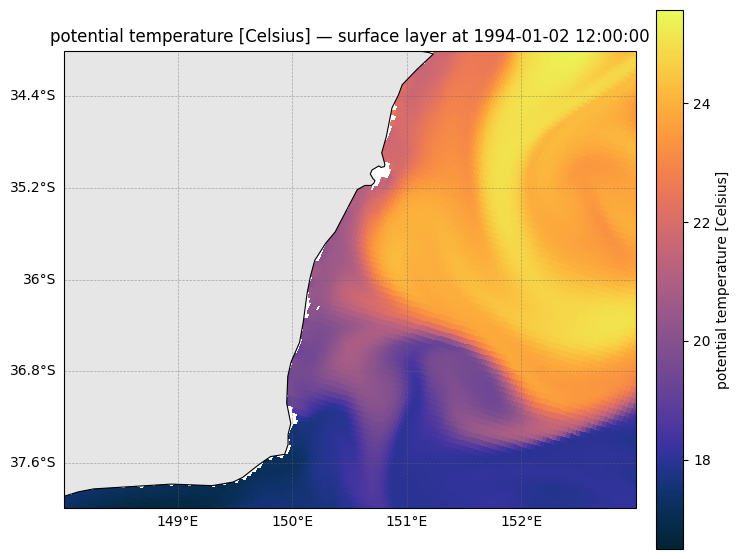

In [10]:
fig_surface, ax_surface, temp_surface = plot_horizontal_slice(
    ds,
    variable="temp",
    time=PLOT_TIME,
    depth_m=None,
    extent=EXTENT,
    cmap=cmocean.cm.thermal,
)

Requested time: 1994-01-02T12:00:00.000000000; plotting nearest model time: 1994-01-02T12:00:00.000000000


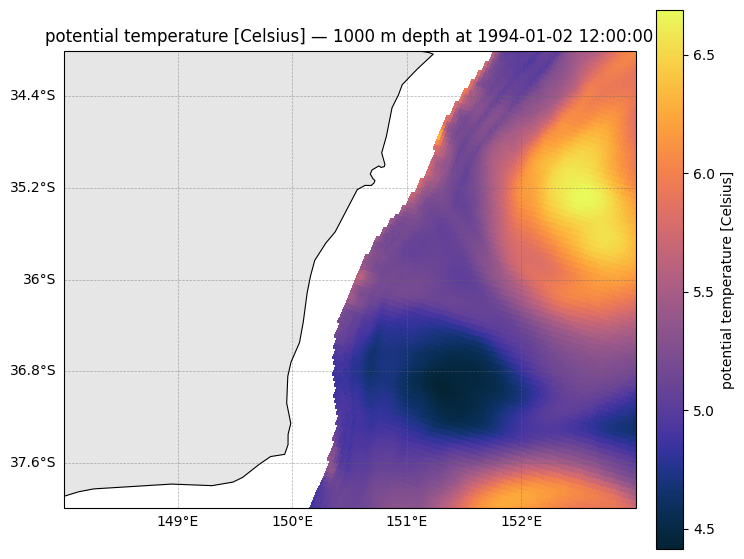

In [12]:
fig_100m, ax_100m, temp_100m = plot_horizontal_slice(
    ds,
    variable="temp",
    time=PLOT_TIME,
    depth_m=1000,
    extent=EXTENT,
    cmap=cmocean.cm.thermal,
)

Requested time: 1994-01-02T12:00:00.000000000; plotting nearest model time: 1994-01-02T12:00:00.000000000


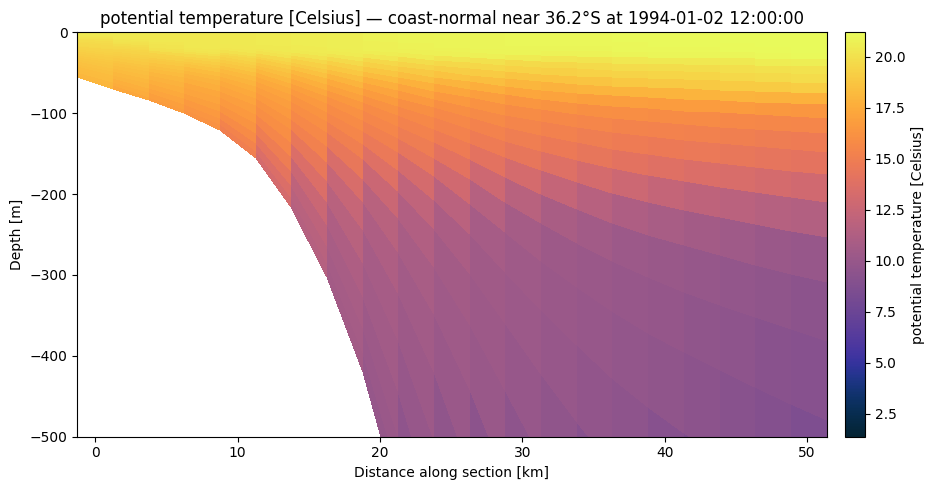

In [17]:
fig_section, ax_section, temp_section = plot_vertical_section(
    ds,
    variable="temp",
    time=PLOT_TIME,
    section_mode="coast_normal",
    target_lat=-36.2,
    offshore_km=50,
    depth_limits=(-500, 0),
    cmap=cmocean.cm.thermal,
)

### Optional: section between two endpoints

Set `RUN_ENDPOINT_EXAMPLE = True` after choosing endpoints inside `EXTENT`. The section follows unique nearest cells on the variable's native ROMS grid; it is not bilinearly interpolated onto an exact geographic line. 

Requested time: 1994-01-02T12:00:00.000000000; plotting nearest model time: 1994-01-02T12:00:00.000000000


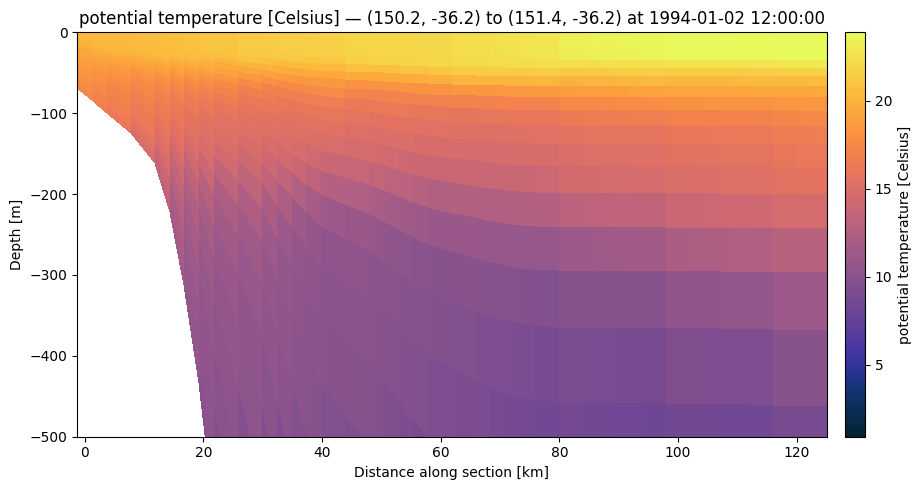

In [ ]:
RUN_ENDPOINT_EXAMPLE = False

if RUN_ENDPOINT_EXAMPLE:
    fig_endpoints, ax_endpoints, temp_endpoints = plot_vertical_section(
        ds,
        variable="temp",
        time=PLOT_TIME,
        section_mode="endpoints",
        start=(150.2, -36.2),
        end=(151.4, -36.2),
        depth_limits=(-500, 0),
        cmap=cmocean.cm.thermal,
    )

## 6. Close the dataset

When finished, release the open file handles with `ds.close()`.

In [ ]:
# ds.close()